# 01 — Data Loading & Overview

**IEEE-CIS Fraud Detection**

This notebook performs the initial exploration of the raw dataset:

1. Load `train_transaction.csv` and `train_identity.csv`
2. Merge on `TransactionID` (LEFT join)
3. Inspect schema, dtypes, shapes
4. Examine target distribution (`isFraud`)
5. Check identity coverage and its relationship to fraud
6. Verify uniqueness of `TransactionID`
7. Profile memory usage
8. Save overview figures to `reports/figures/`

> **No cleaning or modelling happens here.** This is purely observational.

---
## 1 · Imports & Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ── Paths ────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent  # assumes notebook is run from notebooks/
RAW_DIR      = PROJECT_ROOT / "data" / "raw"
FIG_DIR      = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ── Display options ──────────────────────────────────────
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
%matplotlib inline

print(f"Project root : {PROJECT_ROOT}")
print(f"Raw data dir : {RAW_DIR}")
print(f"Figures dir  : {FIG_DIR}")

Project root : c:\Users\User\Documents\pfa\ieee_fraud_project
Raw data dir : c:\Users\User\Documents\pfa\ieee_fraud_project\data\raw
Figures dir  : c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures


---
## 2 · Load Raw CSV Files

We load the two source files provided by the Kaggle competition:
- **`train_transaction.csv`** — one row per transaction (≈ 590 k rows, 394 columns)
- **`train_identity.csv`** — device / browser metadata, available for a *subset* of transactions (≈ 144 k rows, 41 columns)

In [2]:
%%time

txn_path = RAW_DIR / "train_transaction.csv"
idn_path = RAW_DIR / "train_identity.csv"

# Verify files exist
for p in [txn_path, idn_path]:
    if not p.exists():
        raise FileNotFoundError(f"Missing: {p}")

txn = pd.read_csv(txn_path)
idn = pd.read_csv(txn_path)  # placeholder — replaced below
idn = pd.read_csv(idn_path)

print("Loaded successfully.")

Loaded successfully.
CPU times: total: 14.1 s
Wall time: 14.2 s


---
## 3 · Shapes of Source Files

In [3]:
print(f"train_transaction : {txn.shape[0]:>10,} rows  ×  {txn.shape[1]:>4} columns")
print(f"train_identity    : {idn.shape[0]:>10,} rows  ×  {idn.shape[1]:>4} columns")
print(f"\nIdentity coverage : {idn.shape[0] / txn.shape[0]:.1%} of transactions have identity data")

train_transaction :    590,540 rows  ×   394 columns
train_identity    :    144,233 rows  ×    41 columns

Identity coverage : 24.4% of transactions have identity data


> **Observation:** Only about 24 % of transactions have associated identity/device data.  
> The LEFT join will introduce many NaN values in the identity columns for the remaining 76 %.

---
## 4 · Merge on TransactionID (LEFT Join)

We use a **LEFT join** to keep every transaction row.  
The identity columns will be `NaN` for transactions without a matching identity record.

In [4]:
df = txn.merge(idn, on="TransactionID", how="left")

print(f"Merged shape : {df.shape[0]:,} rows  ×  {df.shape[1]} columns")
assert len(df) == len(txn), "Row count changed after LEFT join — check for duplicate TransactionIDs in identity!"
print("✓ Row count preserved after LEFT join.")

Merged shape : 590,540 rows  ×  434 columns
✓ Row count preserved after LEFT join.


In [5]:
df.head(5)

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2,dist1,dist2,P_emaildomain,R_emaildomain,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,...,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987000,0,86400,68.5000,W,13926,NaN,150.0000,discover,142.0000,credit,315.0000,87.0000,19.0000,NaN,NaN,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,2.0000,0.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0000,W,2755,404.0000,150.0000,mastercard,102.0000,credit,325.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0000,W,4663,490.0000,150.0000,visa,166.0000,debit,330.0000,87.0000,287.0000,NaN,outlook.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0000,W,18132,567.0000,150.0000,mastercard,117.0000,debit,476.0000,87.0000,NaN,NaN,yahoo.com,NaN,2.0000,5.0000,0.0000,0.0000,0.0000,4.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,25.0000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0000,H,4497,514.0000,150.0000,mastercard,102.0000,credit,420.0000,87.0000,NaN,NaN,gmail.com,NaN,1.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,0.0000,1.0000,...,100.0000,NotFound,NaN,-480.0000,New,NotFound,166.0000,NaN,542.0000,144.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,New,NotFound,Android 7.0,samsung browser 6.2,32.0000,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M


---
## 5 · Column Inspection & Data Types

Let's see the full column list grouped by dtype.

In [6]:
print(f"Total columns: {len(df.columns)}")
print()
print("Dtype breakdown:")
print(df.dtypes.value_counts().to_string())

Total columns: 434

Dtype breakdown:
float64    399
object      31
int64        4


In [7]:
# Numeric vs object columns
num_cols = df.select_dtypes(include="number").columns.tolist()
obj_cols = df.select_dtypes(include="object").columns.tolist()

print(f"Numeric columns : {len(num_cols)}")
print(f"Object columns  : {len(obj_cols)}")
print(f"\nObject columns: {obj_cols}")

Numeric columns : 403
Object columns  : 31

Object columns: ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [8]:
# Quick per-column summary: non-null counts and dtypes
info_df = pd.DataFrame({
    "dtype": df.dtypes,
    "non_null": df.notna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "nunique": df.nunique(),
})
info_df.sort_values("null_pct", ascending=False).head(30)

,dtype,non_null,null_pct,nunique
id_24,float64,4747,99.2000,12
id_25,float64,5132,99.1300,341
id_26,float64,5163,99.1300,95
id_21,float64,5159,99.1300,490
id_08,float64,5155,99.1300,94
id_07,float64,5155,99.1300,84
id_27,object,5169,99.1200,2
id_23,object,5169,99.1200,3
id_22,float64,5169,99.1200,25
dist2,float64,37627,93.6300,1751


> **Observation:** Many columns (especially `V`-columns and `id_*` columns) have very high missingness.  
> During cleaning (notebook 04), we will drop columns above a 50 % missing threshold.

---
## 6 · Target Distribution (`isFraud`)

The target is binary:  
- `0` → legitimate transaction  
- `1` → fraud

In [9]:
target = "isFraud"

# Class counts
class_counts = df[target].value_counts().sort_index()
class_pct    = df[target].value_counts(normalize=True).sort_index() * 100

summary = pd.DataFrame({"count": class_counts, "percent": class_pct.round(2)})
summary.index = ["Legit (0)", "Fraud (1)"]
print(summary.to_string())
print(f"\nFraud rate: {df[target].mean():.4%}")

            count  percent
Legit (0)  569877  96.5000
Fraud (1)   20663   3.5000

Fraud rate: 3.4990%


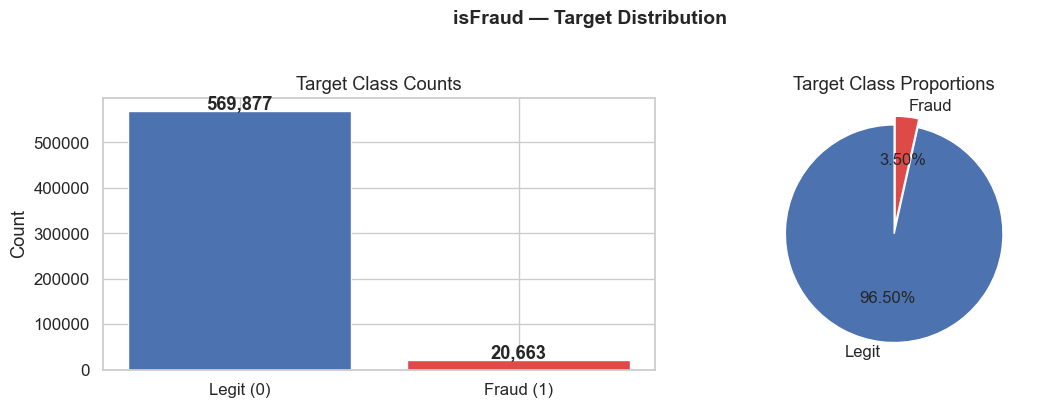

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures\fig_target_distribution.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
colors = ["#4C72B0", "#DD4A48"]
axes[0].bar(["Legit (0)", "Fraud (1)"], class_counts.values, color=colors, edgecolor="white")
axes[0].set_ylabel("Count")
axes[0].set_title("Target Class Counts")
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + len(df) * 0.005, f"{v:,}", ha="center", fontweight="bold")

# Pie chart
axes[1].pie(
    class_counts.values,
    labels=["Legit", "Fraud"],
    autopct="%1.2f%%",
    colors=colors,
    startangle=90,
    explode=(0, 0.08),
    textprops={"fontsize": 12},
)
axes[1].set_title("Target Class Proportions")

fig.suptitle("isFraud — Target Distribution", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {FIG_DIR / 'fig_target_distribution.png'}")

> **Observation:** The dataset is **heavily imbalanced** — fraud represents only ~3.5 % of all transactions.  
> Plain accuracy will be a misleading metric.  
> We must optimise for **PR-AUC**, **Recall**, and **F1** instead.

---
## 7 · `TransactionDT` Overview

`TransactionDT` is the number of seconds elapsed since an undisclosed reference point.  
It encodes the chronological order of transactions and will be used for time-based splitting.

In [11]:
dt = df["TransactionDT"]
print(f"min          : {dt.min():>12,}")
print(f"max          : {dt.max():>12,}")
print(f"range (sec)  : {dt.max() - dt.min():>12,}")
print(f"range (days) : {(dt.max() - dt.min()) / 86400:>12.1f}")

min          :       86,400
max          :   15,811,131
range (sec)  :   15,724,731
range (days) :        182.0


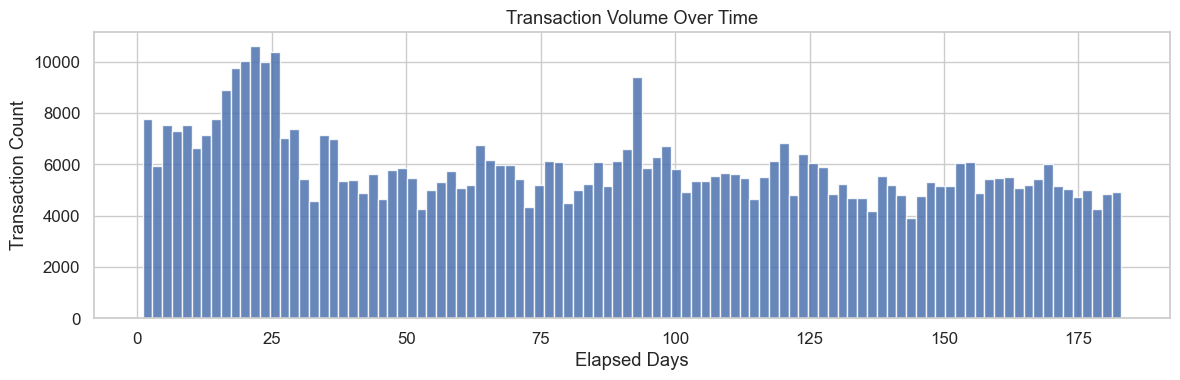

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures\fig_transaction_volume_over_time.png


In [12]:
fig, ax = plt.subplots(figsize=(12, 4))

# Convert to elapsed days for readability
elapsed_days = dt / 86400

ax.hist(elapsed_days, bins=100, color="#4C72B0", edgecolor="white", alpha=0.85)
ax.set_xlabel("Elapsed Days")
ax.set_ylabel("Transaction Count")
ax.set_title("Transaction Volume Over Time")

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_transaction_volume_over_time.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {FIG_DIR / 'fig_transaction_volume_over_time.png'}")

> **Observation:** The data spans roughly **6 months** of transactions.  
> The distribution shows periodic patterns (likely weekly cycles).  
> We will use `TransactionDT` for a chronological train/valid/test split.

---
## 8 · `TransactionAmt` Overview

In [13]:
amt = df["TransactionAmt"]
print(amt.describe().to_string())
print(f"\nAmounts > $1000  : {(amt > 1000).sum():,}  ({(amt > 1000).mean():.2%})")
print(f"Amounts > $10000 : {(amt > 10000).sum():,}  ({(amt > 10000).mean():.2%})")

count   590540.0000
mean       135.0272
std        239.1625
min          0.2510
25%         43.3210
50%         68.7690
75%        125.0000
max      31937.3910

Amounts > $1000  : 7,267  (1.23%)
Amounts > $10000 : 2  (0.00%)


C:\Users\User\AppData\Local\Temp\ipykernel_13556\408071324.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x="isFraud", y="TransactionAmt", ax=axes[1],


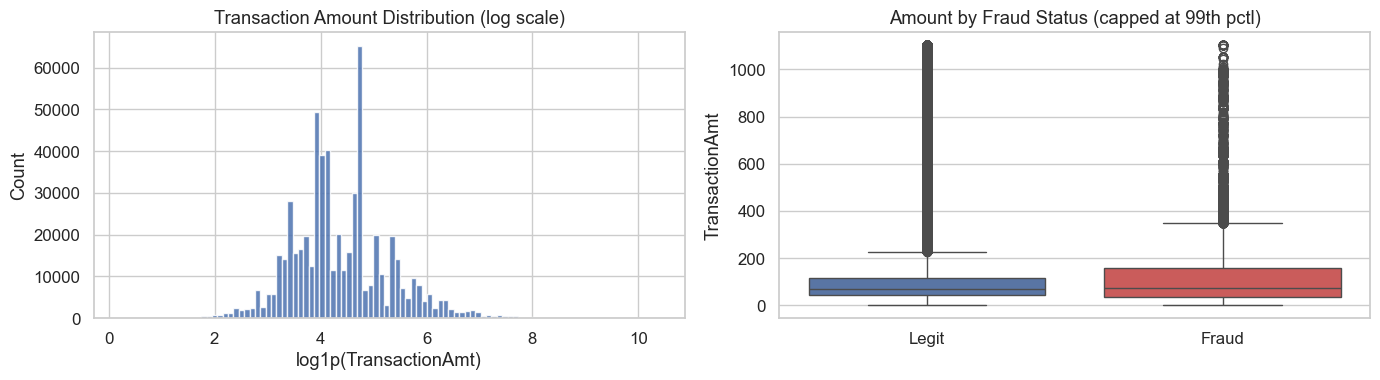

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures\fig_transaction_amount.png


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Log-scale histogram
axes[0].hist(np.log1p(amt), bins=100, color="#4C72B0", edgecolor="white", alpha=0.85)
axes[0].set_xlabel("log1p(TransactionAmt)")
axes[0].set_ylabel("Count")
axes[0].set_title("Transaction Amount Distribution (log scale)")

# Fraud vs legit comparison (boxplot, capped at 99th percentile)
cap = amt.quantile(0.99)
plot_df = df[["TransactionAmt", "isFraud"]].copy()
plot_df = plot_df[plot_df["TransactionAmt"] <= cap]
plot_df["isFraud"] = plot_df["isFraud"].map({0: "Legit", 1: "Fraud"})

sns.boxplot(data=plot_df, x="isFraud", y="TransactionAmt", ax=axes[1],
            palette={"Legit": "#4C72B0", "Fraud": "#DD4A48"})
axes[1].set_title("Amount by Fraud Status (capped at 99th pctl)")
axes[1].set_xlabel("")

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_transaction_amount.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {FIG_DIR / 'fig_transaction_amount.png'}")

> **Observation:** Transaction amounts are heavily right-skewed — a `log1p` transform will be useful.  
> Fraudulent transactions tend to have different amount patterns compared to legitimate ones.

---
## 9 · Identity Coverage & Fraud Rate

Does having identity data (device/browser info) correlate with fraud rate?  
We flag rows where at least one identity-related column is non-null.

In [15]:
# Identify identity columns: id_* plus DeviceType and DeviceInfo
id_cols = [c for c in df.columns if c.startswith("id_")] + ["DeviceType", "DeviceInfo"]
id_cols = [c for c in id_cols if c in df.columns]

print(f"Identity-related columns found: {len(id_cols)}")
print(id_cols[:10], "..." if len(id_cols) > 10 else "")

Identity-related columns found: 40
['id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10'] ...


In [16]:
# has_identity = True if at least one id_* / Device* column is non-null
df["has_identity"] = df[id_cols].notna().any(axis=1)

identity_summary = (
    df.groupby("has_identity")[target]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "n_transactions", "sum": "n_fraud", "mean": "fraud_rate"})
)
identity_summary["fraud_rate_pct"] = (identity_summary["fraud_rate"] * 100).round(3)
print(identity_summary.to_string())

              n_transactions  n_fraud  fraud_rate  fraud_rate_pct
has_identity                                                     
False                 446307     9345      0.0209          2.0940
True                  144233    11318      0.0785          7.8470


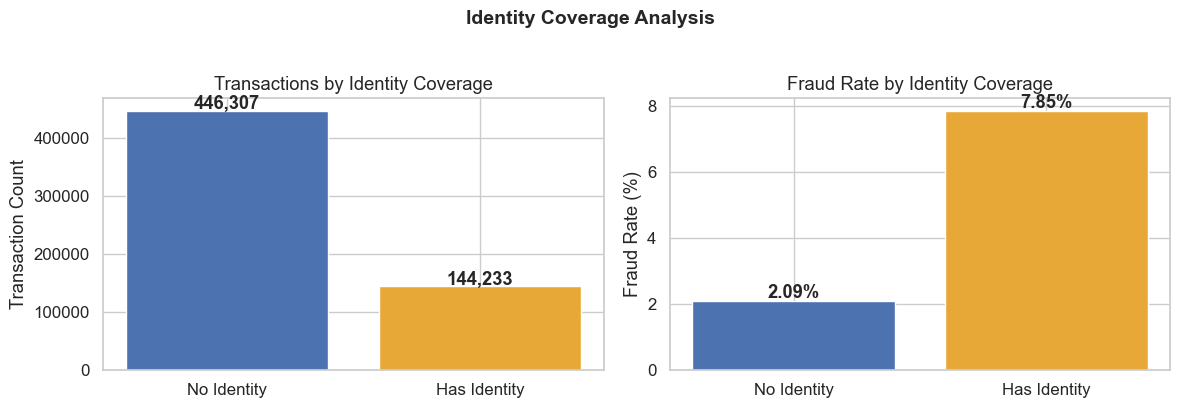

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures\fig_identity_coverage.png


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Counts
labels = ["No Identity", "Has Identity"]
counts = [df[~df["has_identity"]][target].count(), df[df["has_identity"]][target].count()]
axes[0].bar(labels, counts, color=["#4C72B0", "#E8A838"], edgecolor="white")
axes[0].set_ylabel("Transaction Count")
axes[0].set_title("Transactions by Identity Coverage")
for i, v in enumerate(counts):
    axes[0].text(i, v + len(df) * 0.005, f"{v:,}", ha="center", fontweight="bold")

# Fraud rates
fraud_rates = [
    df[~df["has_identity"]][target].mean() * 100,
    df[df["has_identity"]][target].mean() * 100,
]
axes[1].bar(labels, fraud_rates, color=["#4C72B0", "#E8A838"], edgecolor="white")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_title("Fraud Rate by Identity Coverage")
for i, v in enumerate(fraud_rates):
    axes[1].text(i, v + 0.1, f"{v:.2f}%", ha="center", fontweight="bold")

fig.suptitle("Identity Coverage Analysis", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_identity_coverage.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {FIG_DIR / 'fig_identity_coverage.png'}")

> **Observation:** Transactions **with** identity data tend to have a noticeably different fraud rate  
> than those without.  The `has_identity` flag itself may be a useful binary feature.

---
## 10 · `ProductCD` and Card Columns Overview

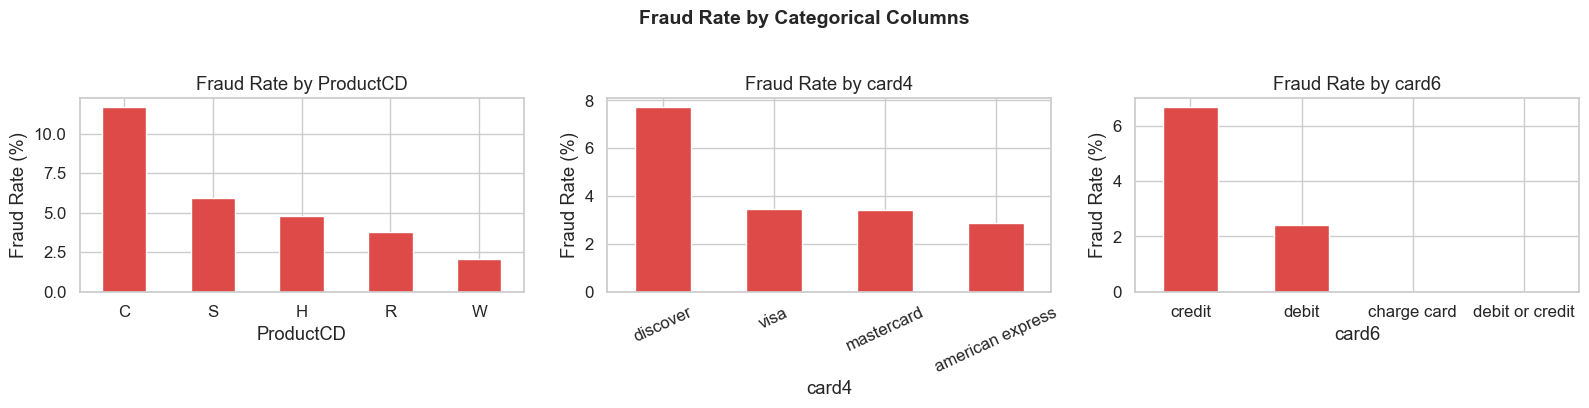

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures\fig_fraud_by_categories.png


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# ProductCD
if "ProductCD" in df.columns:
    fraud_by_product = df.groupby("ProductCD")[target].mean().sort_values(ascending=False) * 100
    fraud_by_product.plot.bar(ax=axes[0], color="#DD4A48", edgecolor="white")
    axes[0].set_title("Fraud Rate by ProductCD")
    axes[0].set_ylabel("Fraud Rate (%)")
    axes[0].tick_params(axis="x", rotation=0)

# card4 (visa, mastercard, etc.)
if "card4" in df.columns:
    fraud_by_card4 = df.groupby("card4")[target].mean().sort_values(ascending=False) * 100
    fraud_by_card4.plot.bar(ax=axes[1], color="#DD4A48", edgecolor="white")
    axes[1].set_title("Fraud Rate by card4")
    axes[1].set_ylabel("Fraud Rate (%)")
    axes[1].tick_params(axis="x", rotation=25)

# card6 (debit, credit)
if "card6" in df.columns:
    fraud_by_card6 = df.groupby("card6")[target].mean().sort_values(ascending=False) * 100
    fraud_by_card6.plot.bar(ax=axes[2], color="#DD4A48", edgecolor="white")
    axes[2].set_title("Fraud Rate by card6")
    axes[2].set_ylabel("Fraud Rate (%)")
    axes[2].tick_params(axis="x", rotation=0)

fig.suptitle("Fraud Rate by Categorical Columns", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_fraud_by_categories.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {FIG_DIR / 'fig_fraud_by_categories.png'}")

> **Observation:** Fraud rate varies significantly across `ProductCD` categories and card types.  
> These categorical columns carry predictive signal and should be encoded carefully.

---
## 11 · TransactionID Duplicate Check

In [19]:
n_duplicates = df["TransactionID"].duplicated().sum()
print(f"Duplicate TransactionIDs: {n_duplicates}")

if n_duplicates == 0:
    print("✓ TransactionID is unique — safe to use as row identifier.")
else:
    print(f"⚠ Found {n_duplicates} duplicate TransactionIDs — investigate before modelling!")
    print(df[df["TransactionID"].duplicated(keep=False)].head(10))

Duplicate TransactionIDs: 0
✓ TransactionID is unique — safe to use as row identifier.


> **Observation:** `TransactionID` is unique after the LEFT join, confirming there are no  
> duplicate keys in the identity table that would inflate the row count.

---
## 12 · Missing Values Overview

In [20]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

print(f"Columns with  0% missing   : {(missing_pct == 0).sum()}")
print(f"Columns with  >0–25% missing : {((missing_pct > 0) & (missing_pct <= 25)).sum()}")
print(f"Columns with 25–50% missing : {((missing_pct > 25) & (missing_pct <= 50)).sum()}")
print(f"Columns with 50–75% missing : {((missing_pct > 50) & (missing_pct <= 75)).sum()}")
print(f"Columns with 75–100% missing: {(missing_pct > 75).sum()}")
print(f"\nTotal columns: {len(missing_pct)}")

Columns with  0% missing   : 21
Columns with  >0–25% missing : 162
Columns with 25–50% missing : 38
Columns with 50–75% missing : 6
Columns with 75–100% missing: 208

Total columns: 435


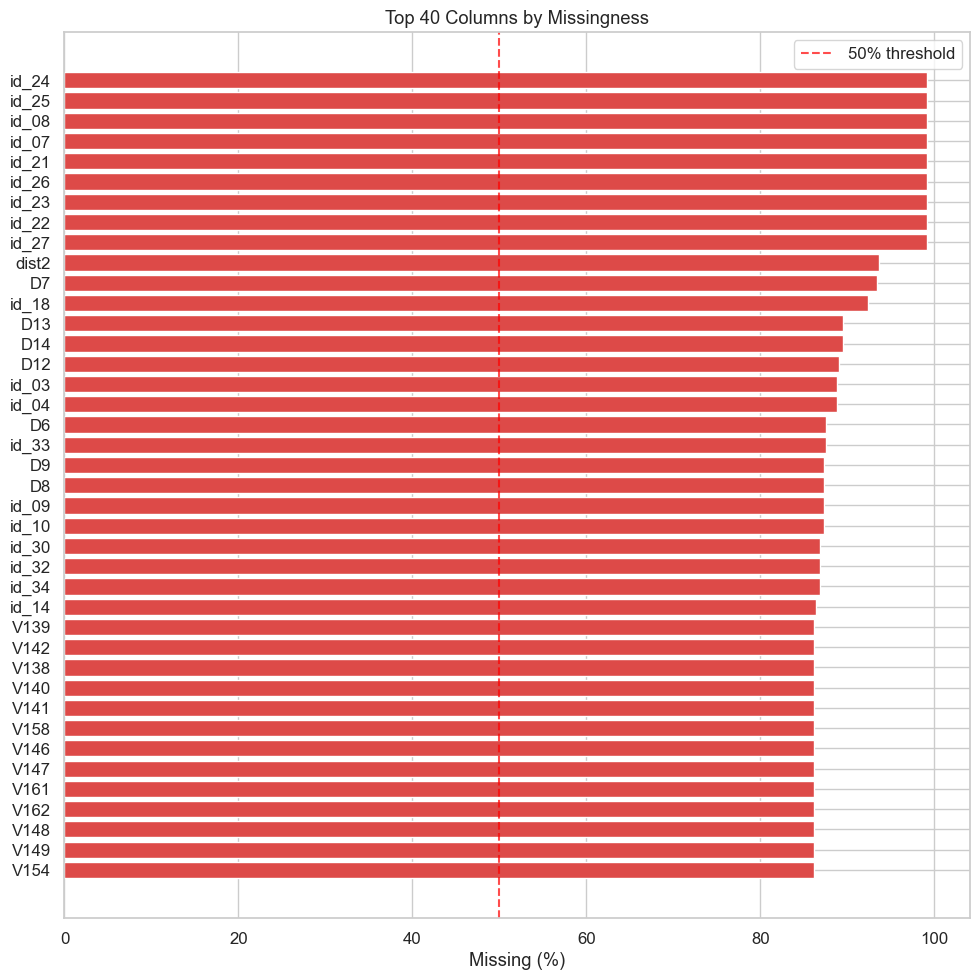

Saved → c:\Users\User\Documents\pfa\ieee_fraud_project\reports\figures\fig_missing_values_top40.png


In [21]:
# Top 40 most-missing columns
fig, ax = plt.subplots(figsize=(10, 10))

top_missing = missing_pct.head(40)
colors = ["#DD4A48" if v > 50 else "#E8A838" if v > 25 else "#4C72B0" for v in top_missing.values]

ax.barh(top_missing.index[::-1], top_missing.values[::-1], color=colors[::-1], edgecolor="white")
ax.set_xlabel("Missing (%)")
ax.set_title("Top 40 Columns by Missingness")
ax.axvline(x=50, color="red", linestyle="--", alpha=0.7, label="50% threshold")
ax.legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "fig_missing_values_top40.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {FIG_DIR / 'fig_missing_values_top40.png'}")

> **Observation:** A large number of columns exceed the 50 % missing threshold (shown in red).  
> These will be dropped during cleaning unless they carry strong predictive signal.  
> The orange / blue columns have moderate / low missingness and will be imputed.

---
## 13 · Memory Usage

In [22]:
mem_by_dtype = df.memory_usage(deep=True).sum() / 1e6
print(f"Total memory usage: {mem_by_dtype:.1f} MB")
print()

# Per-dtype breakdown
mem_breakdown = (
    df.memory_usage(deep=True)
    .drop("Index")
    .groupby(df.dtypes)
    .sum()
    .sort_values(ascending=False)
    / 1e6
)
print("Memory by dtype (MB):")
print(mem_breakdown.round(1).to_string())
print()
print("Tip: Converting object columns to 'category' and float64 → float32")
print("could reduce memory by ~50%. This will be done during cleaning.")

Total memory usage: 2692.4 MB

Memory by dtype (MB):
float64   1885.0000
object     787.9000
int64       18.9000
bool         0.6000

Tip: Converting object columns to 'category' and float64 → float32
could reduce memory by ~50%. This will be done during cleaning.


> **Observation:** The merged dataset is large (several hundred MB).  
> Type-casting (float64→float32, object→category) and saving as Parquet  
> will substantially reduce memory and disk footprint in subsequent notebooks.

---
## 14 · Key Columns Quick Stats

In [23]:
key_cols = [
    "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card4", "card6",
    "addr1", "addr2",
    "P_emaildomain", "R_emaildomain",
    "D1", "D2", "D3",
    "DeviceType", "DeviceInfo",
]
key_cols = [c for c in key_cols if c in df.columns]

summary_stats = pd.DataFrame({
    "dtype": df[key_cols].dtypes,
    "null_%": (df[key_cols].isna().mean() * 100).round(2),
    "nunique": df[key_cols].nunique(),
    "sample": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in key_cols],
})
summary_stats

,dtype,null_%,nunique,sample
TransactionDT,int64,0.0000,573349,86400
TransactionAmt,float64,0.0000,20902,68.5000
ProductCD,object,0.0000,5,W
card1,int64,0.0000,13553,13926
card4,object,0.2700,4,discover
card6,object,0.2700,4,credit
addr1,float64,11.1300,332,315.0000
addr2,float64,11.1300,74,87.0000
P_emaildomain,object,15.9900,59,gmail.com
R_emaildomain,object,76.7500,60,gmail.com


---
## 15 · Summary & Next Steps

### What we learned

| Finding | Detail |
|---------|--------|
| **Dataset size** | ~590 k rows × 430+ columns after merge |
| **Target imbalance** | Fraud ≈ 3.5 % — must use PR-AUC, Recall, F1 |
| **Identity coverage** | ~24 % of transactions have device/browser data |
| **Missingness** | Many columns >50 % null — will drop during cleaning |
| **Time span** | ~6 months of transactions via `TransactionDT` |
| **TransactionID** | Unique — safe row identifier |
| **Memory** | Large footprint — dtype downcasting + Parquet recommended |

### Next notebook

→ **`02_missing_values_and_quality_checks.ipynb`** — detailed missingness profiling,  
column-level quality checks, and decisions on what to keep / drop.

In [24]:
# Clean up the helper column before closing
df.drop(columns=["has_identity"], inplace=True, errors="ignore")
print("Notebook 01 complete. ✓")

Notebook 01 complete. ✓
